# Parte 0 · Preparación de los datos de CDNOW

**Autora:** Sofía Isabela Sandoval Vásquez · Grupo 1

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por la autora.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datos import cargar_cdnow, resumen_clientes

FIN_CALIB, FIN_HOLDOUT = "1997-09-30", "1998-06-30"

## 0.1 y 0.2 · Transacciones por día y tiempo en semanas

Se agrupan las compras de un mismo cliente en un mismo día como una sola transacción. El tiempo se mide en semanas (días / 7) desde el 1 de enero de 1997.

In [2]:
crudo = pd.read_csv("../data/CDNOW_sample.txt", sep=r"\s+", header=None)
trans = cargar_cdnow("../data/CDNOW_sample.txt")

print(f"Registros originales:            {len(crudo):,}")
print(f"Transacciones (1 por cliente-día): {len(trans):,}")
print(f"Clientes:                        {trans['cliente'].nunique():,}")
trans.head()

Registros originales:            6,919
Transacciones (1 por cliente-día): 6,696
Clientes:                        2,357


,cliente,fecha,semana,cds,monto
0,1,1997-01-01,0.000000,2,29.33
1,1,1997-01-18,2.428571,2,29.73
2,1,1997-08-02,30.428571,1,14.96
3,1,1997-12-12,49.285714,2,26.48
4,2,1997-01-01,0.000000,3,63.34


## 0.3 · Resumen por cliente: x, tx, T y x*

- **x**: compras repetidas en calibración (sin contar la primera).
- **tx**: semana de la última compra en calibración, medida desde la primera.
- **T**: semanas entre la primera compra y el 30 de septiembre de 1997.
- **x\***: compras en el holdout (1 de octubre de 1997 – 30 de junio de 1998).

In [3]:
res = resumen_clientes(trans, FIN_CALIB, FIN_HOLDOUT)
res.head()

,cliente,x,tx,T,x_star,semana_primera
0,1,2,30.428571,38.857143,1,0.0
1,2,1,1.714286,38.857143,0,0.0
2,3,0,0.000000,38.857143,0,0.0
3,4,0,0.000000,38.857143,0,0.0
4,5,0,0.000000,38.857143,0,0.0


In [4]:
res[["x", "tx", "T", "x_star"]].describe().round(2)

,x,tx,T,x_star
count,2357.00,2357.00,2357.00,2357.00
mean,1.04,6.85,32.72,0.80
std,2.19,10.73,3.33,2.06
min,0.00,0.00,27.00,0.00
25%,0.00,0.00,29.86,0.00
50%,0.00,0.00,32.71,0.00
75%,1.00,12.00,35.43,1.00
max,29.00,38.43,38.86,34.00


In [5]:
print(f"Compras repetidas en calibración: {res['x'].sum():,}")
print(f"Compras en el holdout:           {res['x_star'].sum():,}")

Compras repetidas en calibración: 2,457
Compras en el holdout:           1,882


### Verificación contra `lifetimes`

El paquete `lifetimes` incluye el resumen de CDNOW que usaron Fader, Hardie y Lee. Se usa solo para verificar que nuestro (x, tx, T) es correcto.

In [6]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from lifetimes.datasets import load_cdnow_summary_data_with_monetary_value

ref = load_cdnow_summary_data_with_monetary_value()
m = res.set_index("cliente").loc[ref.index]

pd.DataFrame({
    "diferencia máxima": [
        (m["x"] - ref["frequency"]).abs().max(),
        (m["tx"] - ref["recency"]).abs().max(),
        (m["T"] - ref["T"]).abs().max(),
    ]
}, index=["x", "tx", "T"])

,diferencia máxima
x,0.000000
tx,0.004286
T,0.004286


x coincide exactamente. En tx y T la diferencia máxima es menor a 0.005 semanas, porque `lifetimes` guarda esos valores redondeados a dos decimales.

## 0.4 · Clientes sin compras repetidas y por qué T cambia

In [7]:
frac_cero = (res["x"] == 0).mean()
print(f"Clientes que no volvieron a comprar en la calibración: {(res['x'] == 0).sum():,} ({frac_cero:.1%})")
print(f"Rango de T: {res['T'].min():.2f} a {res['T'].max():.2f} semanas")

Clientes que no volvieron a comprar en la calibración: 1,411 (59.9%)
Rango de T: 27.00 a 38.86 semanas


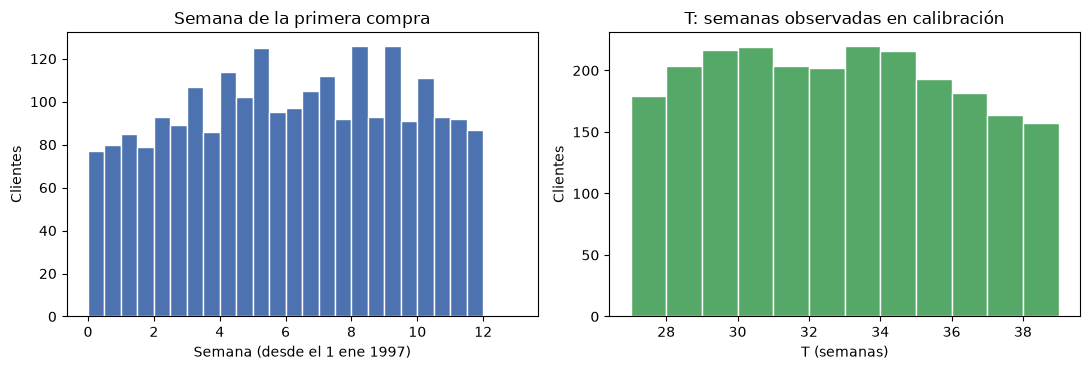

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(res["semana_primera"], bins=np.arange(0, 13.5, 0.5), color="#4C72B0", edgecolor="white")
axes[0].set(title="Semana de la primera compra", xlabel="Semana (desde el 1 ene 1997)", ylabel="Clientes")

axes[1].hist(res["T"], bins=np.arange(27, 40, 1), color="#55A868", edgecolor="white")
axes[1].set(title="T: semanas observadas en calibración", xlabel="T (semanas)", ylabel="Clientes")

plt.tight_layout()
plt.savefig("../figs/parte0_primera_compra_y_T.png", dpi=150)
plt.show()

**Respuesta 0.4.** 1 411 de los 2 357 clientes (59.9 %) no hicieron ninguna compra repetida en las 39 semanas de calibración: la mayoría compró una sola vez. T es distinto para cada cliente porque todos empezaron en una fecha diferente del primer trimestre de 1997, pero la calibración termina el mismo día (30 de septiembre) para todos. Un cliente que llegó el 1 de enero tiene T = 38.86 semanas, y el último en llegar, solo 27. Por eso x = 0 no significa lo mismo para todos: un cliente con T pequeño tuvo menos tiempo para volver a comprar, y el modelo lo toma en cuenta a través de T.